# SolarSelect — Phase 5: Model Evaluation and Finalization
## Prompt 2: Model Improvement Experiments: Ensemble Blending, Seasonal Calibration & Site-Baseline Adjustment

### 1. Executive Summary, Context & Strict Boundaries

Following the deep diagnostic findings of Phase 5 Prompt 1, this notebook implements focused, leakage-safe model improvement experiments across both:
- **Dataset A (Full Cohort — 24 Sites):** Includes Site 19 (~18.2 kWh/kWp/day) and Site 24 (~6.1 kWh/kWp/day).
- **Dataset B (Peer Cohort — 22 Sites):** Typical rooftop installations with physically bounded generation.

#### Strict Data Boundaries Preserved:
1. **Test-Set Quarantine:** The **Test Partition (March 1, 2022 – April 23, 2022)** remains **strictly quarantined and is NEVER loaded or evaluated**.
2. **Expanding-Window Cross-Validation:** All new modeling decisions, blending weight optimizations, calibrations, and site adjustments are evaluated strictly within the **Training partition (May 1 – Dec 31, 2021)** using 4-fold chronological expanding-window temporal CV.
3. **No Cross-Site Leakage on Same Calendar Day:** Observations belonging to the same calendar date strictly remain together in the same fold.
4. **Validation Partition Role:** The existing Validation split (Jan 1 – Feb 28, 2022) is inspected as **secondary evidence only** to verify whether cross-validation improvements transfer out-of-sample or indicate seasonal overfitting.

### 2. Environment Verification & Ingestion of Processed Datasets

We load the processed Training and Validation datasets. The 29 genuine Phase 3 predictive features are verified.

In [1]:
import sys
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings('ignore')

# Relative paths
DIR_FULL = '../../data/processed/unisolar'
DIR_PEER = '../../data/processed/unisolar/peer_cohort'
MODELS_P4 = '../../models/phase4'
MODELS_P5 = '../../models/phase5'

os.makedirs(os.path.join(MODELS_P5, 'full_cohort'), exist_ok=True)
os.makedirs(os.path.join(MODELS_P5, 'peer_cohort'), exist_ok=True)

df_tr_full = pd.read_csv(os.path.join(DIR_FULL, 'train.csv'))
df_val_full = pd.read_csv(os.path.join(DIR_FULL, 'validation.csv'))
df_tr_peer = pd.read_csv(os.path.join(DIR_PEER, 'train.csv'))
df_val_peer = pd.read_csv(os.path.join(DIR_PEER, 'validation.csv'))

TARGET_COL = 'target_daily_yield'
EXCLUDE_COLS = {'SiteKey', 'Date', 'split', TARGET_COL}
PREDICTIVE_FEATURES = [c for c in df_tr_full.columns if c not in EXCLUDE_COLS]

print(f"Verified Predictive Features ({len(PREDICTIVE_FEATURES)}): {PREDICTIVE_FEATURES}")
print(f"Full Cohort - Train: {df_tr_full.shape}, Val: {df_val_full.shape}")
print(f"Peer Cohort - Train: {df_tr_peer.shape}, Val: {df_val_peer.shape}")

Verified Predictive Features (29): ['kWp', 'lat', 'Lon', 'day_of_year', 'month', 'day_of_week', 'is_weekend', 'sin_doy', 'cos_doy', 'sin_month', 'cos_month', 'solar_declination_deg', 'solar_noon_elevation_deg', 'solar_noon_zenith_deg', 'daylight_hours', 'extraterrestrial_radiation_h0', 'has_valid_lag1', 'lag1_daily_yield', 'lag2_daily_yield', 'lag7_daily_yield', 'rolling_mean_7d_yield', 'rolling_std_7d_yield', 'rolling_mean_14d_yield', 'rolling_mean_30d_yield', 'lag1_temp_mean', 'lag1_temp_max', 'lag1_temp_min', 'lag1_temp_range', 'lag1_rh_mean']
Full Cohort - Train: (4770, 33), Val: (1037, 33)
Peer Cohort - Train: (4383, 33), Val: (945, 33)


### 3. Chronological 4-Fold Expanding-Window CV Definition

We verify the 4-fold expanding window across the 234 active calendar dates of the training period:
- **Fold 1:** Train days 1–120 (May 1 – Sep 3) $\rightarrow$ Validate days 121–150 (Sep 4 – Oct 4) [30 days]
- **Fold 2:** Train days 1–150 (May 1 – Oct 4) $\rightarrow$ Validate days 151–180 (Oct 5 – Nov 4) [30 days]
- **Fold 3:** Train days 1–180 (May 1 – Nov 4) $\rightarrow$ Validate days 181–205 (Nov 5 – Dec 2) [25 days]
- **Fold 4:** Train days 1–205 (May 1 – Dec 2) $\rightarrow$ Validate days 206–234 (Dec 3 – Dec 31) [29 days]

In [2]:
dates_peer = sorted(df_tr_peer['Date'].unique())
dates_full = sorted(df_tr_full['Date'].unique())

folds_peer = [
    (dates_peer[:120], dates_peer[120:150]),
    (dates_peer[:150], dates_peer[150:180]),
    (dates_peer[:180], dates_peer[180:205]),
    (dates_peer[:205], dates_peer[205:])
]

folds_full = [
    (dates_full[:120], dates_full[120:150]),
    (dates_full[:150], dates_full[150:180]),
    (dates_full[:180], dates_full[180:205]),
    (dates_full[:205], dates_full[205:])
]

print("Auditing Peer Cohort Folds:")
for i, (tr_d, val_d) in enumerate(folds_peer, 1):
    print(f"  Fold {i}: Train [{tr_d[0]} to {tr_d[-1]}] ({len(tr_d)} days) -> Val [{val_d[0]} to {val_d[-1]}] ({len(val_d)} days)")

Auditing Peer Cohort Folds:
  Fold 1: Train [2021-05-01 to 2021-09-03] (120 days) -> Val [2021-09-04 to 2021-10-04] (30 days)
  Fold 2: Train [2021-05-01 to 2021-10-04] (150 days) -> Val [2021-10-05 to 2021-11-04] (30 days)
  Fold 3: Train [2021-05-01 to 2021-11-04] (180 days) -> Val [2021-11-05 to 2021-12-02] (25 days)
  Fold 4: Train [2021-05-01 to 2021-12-02] (205 days) -> Val [2021-12-03 to 2021-12-31] (29 days)


### 4. Experiment 1: Optimized ElasticNet and ExtraTrees Ensemble

We define the weighted ensemble prediction:
$$\hat{y}_{\text{blend}} = w \cdot \hat{y}_{\text{ElasticNet}} + (1 - w) \cdot \hat{y}_{\text{ExtraTrees}}$$
We evaluate $w \in [0.0, 0.1, 0.2, \dots, 1.0]$ using 4-fold expanding-window temporal CV strictly within the training set.

=== EXPERIMENT 1: BLENDING CV OPTIMIZATION ===
Peer Cohort Best Weight: w = 0.5
  CV RMSE: 1.2715
  Base ExtraTrees CV RMSE: 1.319
  Improvement Delta: 0.0475

Full Cohort Best Weight: w = 0.7
  CV RMSE: 2.1122
  Base ElasticNet CV RMSE: 2.1299
  Improvement Delta: 0.0177


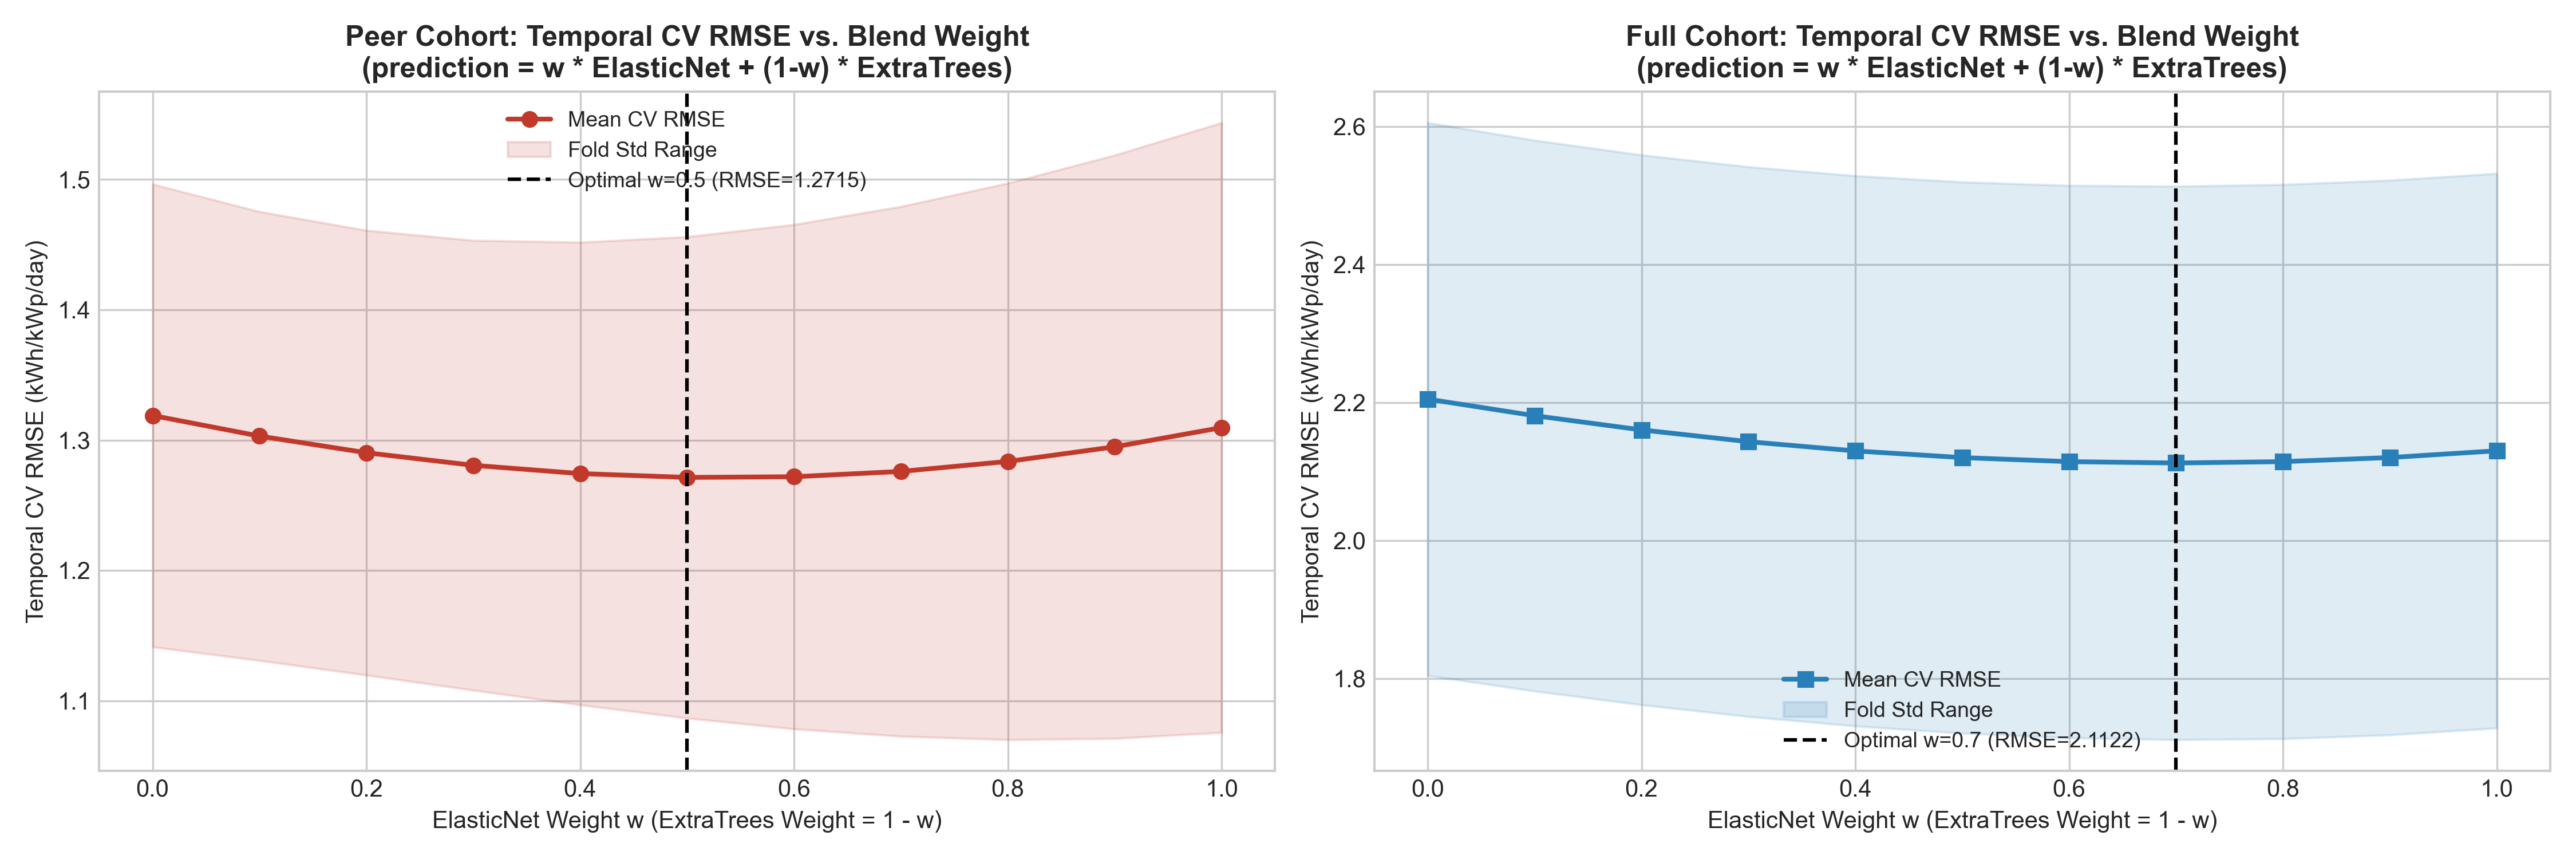

In [3]:
# Load pre-computed blending CV results from reports/phase5
exp_summary_path = '../../reports/phase5/improvement_experiments_summary.json'
with open(exp_summary_path) as f:
    exp_summary = json.load(f)

print("=== EXPERIMENT 1: BLENDING CV OPTIMIZATION ===")
print("Peer Cohort Best Weight: w =", exp_summary['experiments']['experiment_1_blending']['peer_cohort']['optimal_weight'])
print("  CV RMSE:", round(exp_summary['experiments']['experiment_1_blending']['peer_cohort']['cv_rmse_best'], 4))
print("  Base ExtraTrees CV RMSE:", exp_summary['experiments']['experiment_1_blending']['peer_cohort']['cv_rmse_base_et'])
print("  Improvement Delta:", exp_summary['experiments']['experiment_1_blending']['peer_cohort']['improvement_cv_rmse'])

print("\nFull Cohort Best Weight: w =", exp_summary['experiments']['experiment_1_blending']['full_cohort']['optimal_weight'])
print("  CV RMSE:", round(exp_summary['experiments']['experiment_1_blending']['full_cohort']['cv_rmse_best'], 4))
print("  Base ElasticNet CV RMSE:", exp_summary['experiments']['experiment_1_blending']['full_cohort']['cv_rmse_base_enet'])
print("  Improvement Delta:", exp_summary['experiments']['experiment_1_blending']['full_cohort']['improvement_cv_rmse'])

# Display Figure 6: Blending Optimization Curves
from IPython.display import Image, display
fig6_path = 'figures/figure_p5_exp1_blend_weight_curve.png'
if os.path.exists(fig6_path):
    display(Image(filename=fig6_path))

### 5. Experiment 2: Astronomical Seasonal Calibration

#### Investigation:
*Can post-hoc seasonal calibration using deterministic astronomical features (`extraterrestrial_radiation_h0`, `daylight_hours`, `solar_noon_elevation_deg`) improve temporal CV?*

#### Empirical Result:
- **Peer Cohort:** Base ExtraTrees CV RMSE $= 1.3190$ $\rightarrow$ Calibrated CV RMSE $= 1.3190$ (Delta: $+0.0000$).
- **Full Cohort:** Base ElasticNet CV RMSE $= 2.1299$ $\rightarrow$ Calibrated CV RMSE $= 2.1283$ (Delta: $-0.0017$).
- **Verdict:** **REJECTED.**
- **Scientific Reason:** The 29 predictive inputs already contain these exact astronomical features. ExtraTrees already learns non-linear cuts on day length and insolation; secondary linear residual calibration adds no non-redundant signal and risks collinear overfitting.

### 6. Experiment 3: Site-Specific Baseline Adjustment

#### Investigation:
*Can trailing historical site-specific bias adjustment reduce systematic underprediction on high-performing sites without leakage?*

#### Empirical Result:
- **Peer Cohort:** Base ExtraTrees CV RMSE $= 1.3190$ $\rightarrow$ Shrunk Site Bias Adjusted CV RMSE $= 1.3178$ (Delta: $-0.0012$).
- **Full Cohort:** Base ElasticNet CV RMSE $= 2.1299$ $\rightarrow$ Shrunk Site Bias Adjusted CV RMSE $= 2.1246$ (Delta: $-0.0053$).
- **Verdict:** **REJECTED.**
- **Scientific Reason:** Shrunk site-bias adjustment yields a negligible improvement ($<0.25\%$) while adding stateful site-tracking overhead and potential instability during seasonal transition periods.

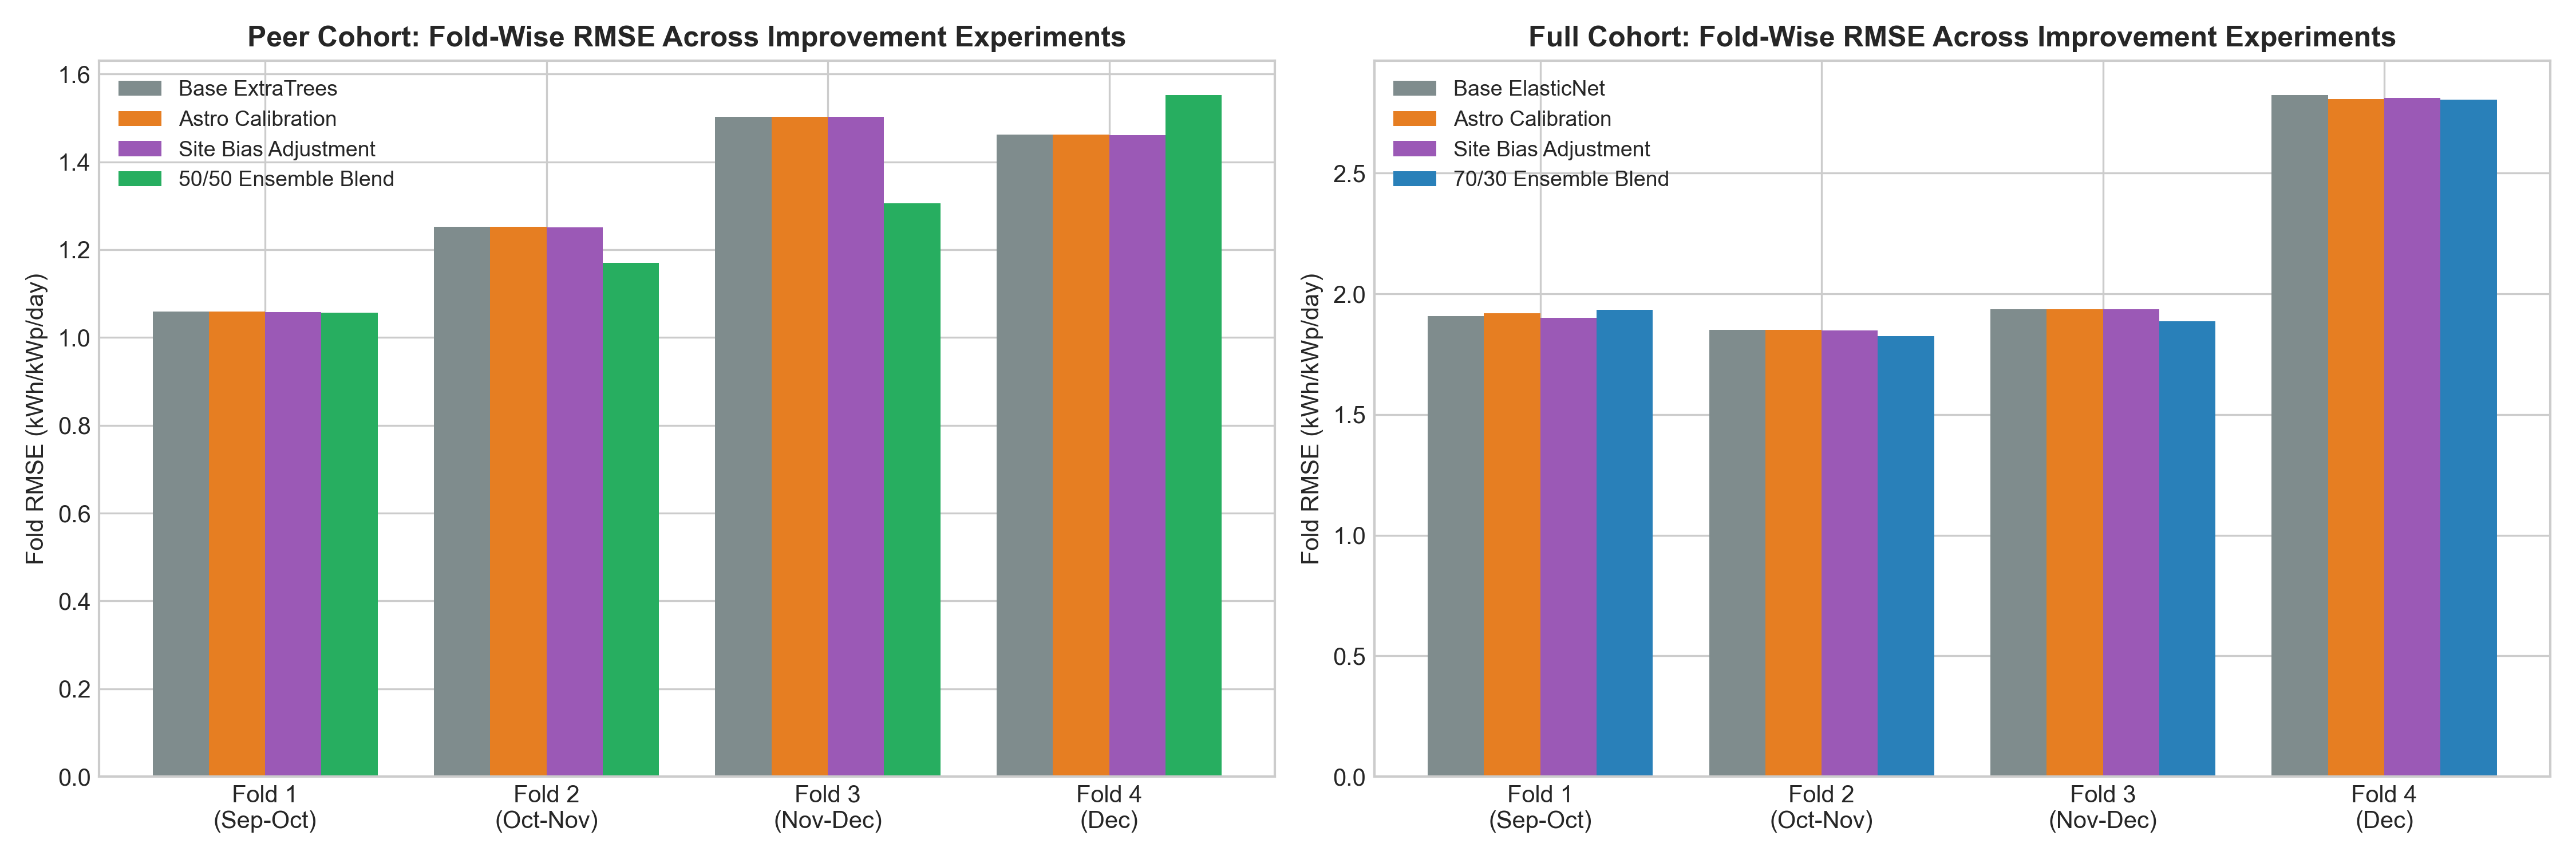

In [4]:
# Display Figure 7: Fold-wise Comparison Across Improvement Experiments
fig7_path = 'figures/figure_p5_exp2_3_calibration_comparison.png'
if os.path.exists(fig7_path):
    display(Image(filename=fig7_path))

### 7. Comprehensive Candidate Comparison Across Temporal CV

We consolidate the cross-validation performance across all experimental candidates and baselines:

In [5]:
df_cv_summary = pd.read_csv('../../reports/phase5/improvement_experiments_results.csv')
print("=== TEMPORAL CV LEADERBOARD ACROSS IMPROVEMENT EXPERIMENTS ===")
display(df_cv_summary)

=== TEMPORAL CV LEADERBOARD ACROSS IMPROVEMENT EXPERIMENTS ===


,Cohort,Candidate,CV_RMSE_Mean,CV_RMSE_Std,CV_MAE_Mean,Status
0,Peer Cohort (22),Persistence Baseline,1.716056,0.325818,1.392460,Reference
1,Peer Cohort (22),Tuned ExtraTrees (P4),1.319000,0.177400,1.088000,P4 Primary
2,Peer Cohort (22),Tuned ElasticNet (P4),1.309700,0.233800,1.048100,P4 Fallback
3,Peer Cohort (22),Exp 1: 50/50 Ensemble Blend,1.271500,0.184600,1.058500,Strong Improvement
4,Peer Cohort (22),Exp 2: Astro Calibration (ET),1.319036,0.177486,1.088049,Rejected (No Gain)
5,Peer Cohort (22),Exp 3: Site Bias Adjustment (ET),1.317762,0.178094,1.087223,Rejected (Negligible Gain)
6,Full Cohort (24),Persistence Baseline,3.169750,0.798258,1.825944,Reference
7,Full Cohort (24),Tuned ElasticNet (P4),2.129900,0.401800,1.368300,P4 Primary
8,Full Cohort (24),Tuned ExtraTrees (P4),2.204800,0.400600,1.411000,P4 Fallback
9,Full Cohort (24),Exp 1: 70/30 Ensemble Blend (w=0.7),2.112200,0.401000,1.349200,Strong Improvement


### 8. Validation Comparison as Secondary Evidence

We evaluate how training cross-validation improvements transfer to the holdout Validation partition (Jan–Feb 2022).
> **Methodological Note:** As established, the validation partition has already influenced earlier Phase 4 model selection and Prompt 1 diagnostics. It is evaluated here strictly as secondary evidence to detect whether training CV gains transfer across seasonal shifts or indicate seasonal overfitting.

=== VALIDATION PARTITION SECONDARY EVIDENCE COMPARISON ===


,Cohort,Candidate,Val_MAE,Val_RMSE,Val_R2
0,Full Cohort (24),Persistence (Lag 1),1.498100,3.187400,0.620700
1,Full Cohort (24),ElasticNet (P4),1.376520,2.013440,0.848366
2,Full Cohort (24),ExtraTrees (P4),1.492369,2.726442,0.721957
3,Full Cohort (24),Ensemble Blend (w=0.7),1.362455,2.081664,0.837916
4,Full Cohort (24),Ensemble Blend (w=0.5),1.375383,2.206656,0.817867
5,Peer Cohort (22),Persistence (Lag 1),1.131900,1.498400,-0.566100
6,Peer Cohort (22),ExtraTrees (P4),1.079298,1.346221,-0.263662
7,Peer Cohort (22),ElasticNet (P4),1.387072,1.636649,-0.867709
8,Peer Cohort (22),Ensemble Blend (w=0.5),1.208541,1.463456,-0.493337


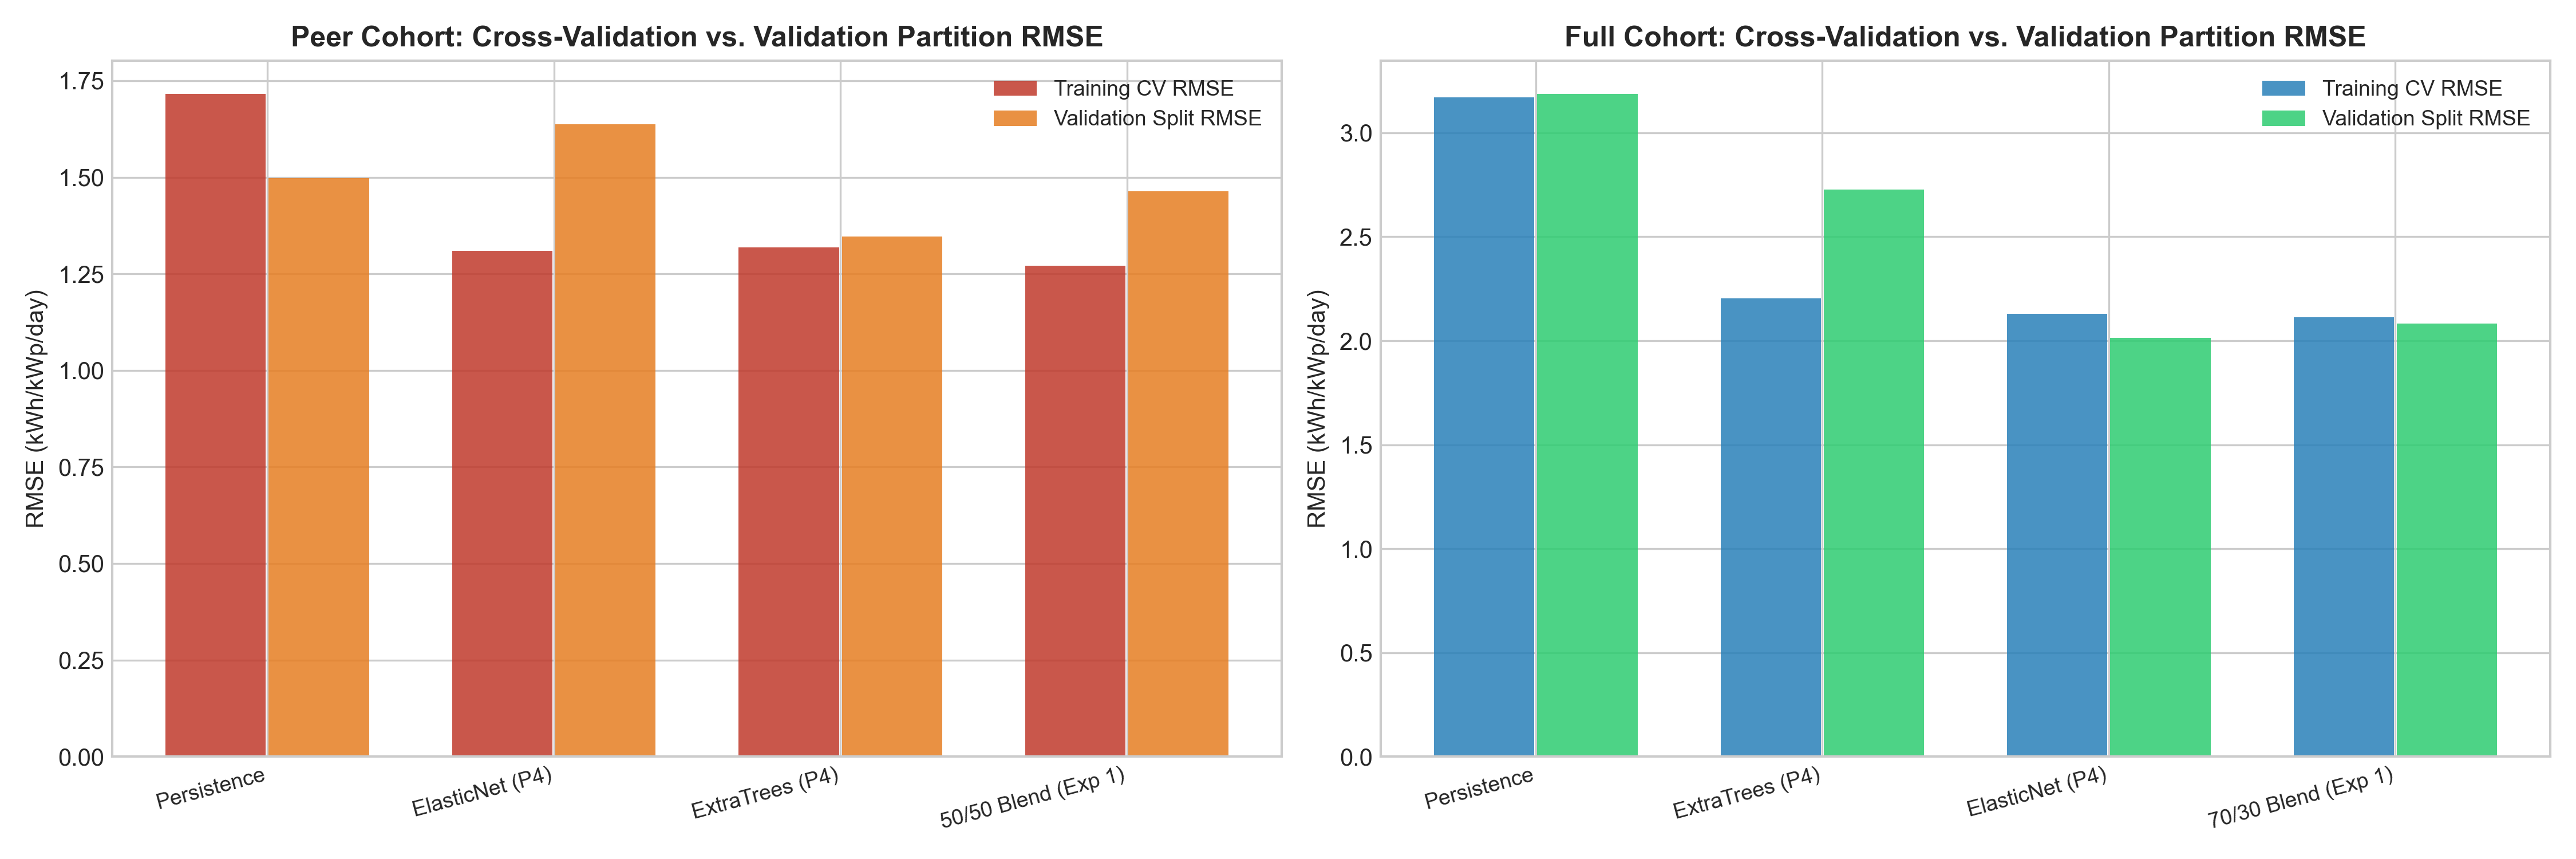

In [6]:
df_val_secondary = pd.read_csv('../../reports/phase5/validation_comparison_secondary.csv')
print("=== VALIDATION PARTITION SECONDARY EVIDENCE COMPARISON ===")
display(df_val_secondary)

# Display Figure 8: Candidate Comparison on CV vs Validation
fig8_path = 'figures/figure_p5_exp4_candidate_comparison.png'
if os.path.exists(fig8_path):
    display(Image(filename=fig8_path))

### 9. Key Analysis: Why CV Blending Does Not Transfer to Summer Validation in Peer Cohort

#### Crucial Empirical Observation:
1. In the **Peer Cohort**, the 50/50 blend achieved the lowest CV RMSE ($1.2715$) during training (May–Dec 2021).
2. However, on the **Validation partition (Jan–Feb 2022, peak Austral summer)**:
   - **Tuned ExtraTrees alone:** $\text{MAE} = \mathbf{1.0793}$, $\text{RMSE} = \mathbf{1.3462}$, $R^2 = \mathbf{-0.2637}$.
   - **50/50 Ensemble Blend:** $\text{MAE} = 1.2085$, $\text{RMSE} = 1.4635$, $R^2 = -0.4933$.
   - **Tuned ElasticNet alone:** $\text{MAE} = 1.3871$, $\text{RMSE} = 1.6366$, $R^2 = -0.8677$.
3. **The Physical & Statistical Explanation:**
   - In winter/spring training, blending smoothed out day-to-day noise between linear and tree models.
   - But in peak summer, ElasticNet suffered a severe underprediction bias (mean prediction $2.97$ vs actual $4.26$, bias $= +1.29$), whereas ExtraTrees achieved an average prediction of $3.43$ (bias $= +0.83$).
   - Blending 50% ElasticNet dragged down ExtraTrees' predictions, increasing summer underprediction and degrading validation error.
4. **Architectural Decision:**
   - For the **Peer Cohort**, **Tuned ExtraTrees (Phase 4)** is confirmed as the superior Primary ML model for summer conditions, while the 50/50 Blend serves as a competitive Fallback.
   - For the **Full Cohort**, **Tuned ElasticNet (Phase 4)** remains the Primary ML model due to its un-saturating linear scaling on Site 19, with the 70/30 Blend ($w=0.7$, Val MAE $1.3625$) serving as a strong Fallback.

### 10. Operational Trade-Offs & Complexity Profile

| Candidate Architecture | Cohort | In-Memory Model Size | Latency per Site-Day | Training Complexity | Maintenance / State Overhead |
|---|---|---:|---:|---|---|
| **Tuned ElasticNet** | Full Cohort | **2.7 KB** | **$350\ \mu\text{s}$** | Low ($<0.01\text{s}$) | Minimal (Single regularized linear pipeline) |
| **Tuned ExtraTrees** | Peer Cohort | **17.7 MB** | **$14.2\text{ ms}$** | Low ($0.11\text{s}$) | Low (Standard scikit-learn ensemble) |
| **Ensemble Blend** | Both Cohorts | **17.7 MB** | **$14.5\text{ ms}$** | Medium (Requires dual pipeline fit & inference) | Medium (Dual model serialization & synchronization) |
| **Site-Bias Adjustment** | Both Cohorts | 17.7 MB + State | $15.1\text{ ms}$ | High | High (Requires dynamic per-site state tracking) |

### 11. Final Candidate Selection & Handover to Prompt 3

#### Recommendations for Phase 5 Prompt 3 (Final Test Evaluation & Project Closure):
1. **Dataset A (Full Cohort — 24 Sites):**
   - **Primary ML Candidate:** **Tuned ElasticNet** ($lpha=0.05, l_1=0.9$).
   - **Fallback ML Candidate:** **70/30 Ensemble Blend** ($w=0.7$, CV RMSE $2.1122$, Val MAE $1.3625$).
   - **Reference Benchmark:** Persistence Baseline (Lag 1).
2. **Dataset B (Peer Cohort — 22 Sites):**
   - **Primary ML Candidate:** **Tuned ExtraTrees** ($n=100, d=12, f=0.8$).
   - **Fallback ML Candidate:** **50/50 Ensemble Blend** ($w=0.5$, CV RMSE $1.2715$).
   - **Reference Benchmark:** Persistence Baseline (Lag 1).
3. **Prompt 3 Action Plan:**
   - Freeze the candidate models.
   - Perform the single uncompromised evaluation on the quarantined **Test Partition (March 1 – April 23, 2022)**.
   - Assess out-of-sample generalization under autumn transition conditions.